# 01 · ฝึกโมเดลจาก expert01 + expert02
เล่มนี้อธิบายและรันการฝึกทีละขั้น ส่วนรายละเอียดคะแนนอยู่ใน
**02_validation_results.ipynb** และ **03_test_results.ipynb**

มี 4 ตัวจำแนก: ก้มหน้า, ไหล่เอียง, จับสูง/ต่ำ/พอดี และควรปรับองศาการสี
สองอาการท่านั่งแยกโมเดลจึงทำนายเป็น 1 พร้อมกันได้
งานคันชักใช้ท่าร่างกายเป็นตัวแทน ไม่ได้วัดนิ้ว มุมคันชัก หรือระยะหย่องโดยตรง

ขั้นตอน: ตรวจข้อมูล → ดู label/feature → TRAIN CV แยกคลิป → shortlist แต่ละครอบครัว →
เลือกด้วย VAL → ล็อกตัวเลือก → fit TRAIN+VAL → บันทึกไฟล์

**เปิด kernel `Python (SawUAI .venv)` แล้ว Run All** ค่าเริ่มต้นเปิดผลรอบนี้ซ้ำได้
ถ้าปรับพารามิเตอร์ให้ตั้ง `TRAIN_NEW=True` เพื่อบันทึกรอบใหม่ โดยยังไม่เปลี่ยนโมเดลเว็บ

## 1.1 · โหลดเครื่องมือและหาโฟลเดอร์

In [1]:
from pathlib import Path
import sys, json
PROJECT = next(p for p in [Path.cwd(), *Path.cwd().parents]
               if (p/'training/src/training/combined_experts.py').exists())
if str(PROJECT/'training') not in sys.path:
    sys.path.insert(0, str(PROJECT/'training'))
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown, Image
from src.training import combined_experts as ce
ce.setup_plots()
pd.set_option('display.max_columns', 25)
pd.set_option('display.max_colwidth', 100)
print('Python:', sys.executable)
print('Training directory:', ce.ROOT)
print('scikit-learn:', ce.sklearn.__version__)
WEB_BEFORE = ce.web_fingerprints()


Python: E:\Kamsuay\SawUAI\training\.venv\Scripts\python.exe
Training directory: E:\Kamsuay\SawUAI\training
scikit-learn: 1.9.1


## 1.2 · ตั้งค่าการทดลอง
`max_depth` จำกัดความลึก, `min_samples_leaf` กำหนดเฟรมขั้นต่ำต่อใบ,
`n_estimators` จำนวนต้นไม้ใน Forest, `max_features` จำนวน feature ที่ให้ลองในแต่ละการแบ่ง
ค้น 24 แบบของ Tree + 24 แบบของ Forest รวมโหมดน้ำหนักสองแบบแล้ว
งานจับเริ่มต้นเปรียบเทียบ feature 2 ตัวกับ 4 ตัวด้วย TRAIN CV
ทั้งหมดเป็นการค้นในขอบเขตที่กำหนด ไม่ใช่รับประกันดีที่สุดในทุกค่าที่เป็นไปได้

In [2]:
SEED = 42
CV_FOLDS = 3
N_JOBS = 2
TREE_GRID = {'max_depth': [2, 3, 4, 6], 'min_samples_leaf': [2, 5, 10]}
FOREST_GRID = {'n_estimators': [150], 'max_depth': [3, 6, None], 'min_samples_leaf': [2, 5], 'max_features': ['sqrt', 1.0]}
TRAIN_NEW = False
RUN = 'combined_experts_20261007_211339_512861'
print('Saved run:', RUN)

Saved run: combined_experts_20261007_211339_512861


## 2.1 · ตรวจความครบและป้องกันข้อมูลรั่ว
ตรวจ SHA256 ของ CSV, label ที่ตรวจโดยคน และ clip/frame/video hash ไม่ซ้ำข้าม split
ขั้นนี้อ่านเฉพาะข้อมูลระบุตัวตนของ test เพื่อตรวจ split ไม่เปิด feature/คำตอบ test เพื่อเลือกโมเดล

In [3]:
summary, manifests = ce.verify_prepared_data()
display(pd.DataFrame([{
    'dataset': name, 'reviewed': m['reviewed_frames'],
    'usable': m['usable_frames'], 'excluded_features': m['unusable_frames'],
    'train': m['splits']['train']['frames'], 'val': m['splits']['val']['frames'],
    'test_reserved': m['splits']['test']['frames']
} for name,m in manifests.items()]))
print('Source:', summary['source_clips'], 'clips /', summary['physical_frames'], 'physical frames')
print('Counts across tasks overlap; do not add them as unique photos.')

,dataset,reviewed,usable,excluded_features,train,val,test_reserved
0,bow_angle_float_body_proxy,558,421,137,261,83,77
1,initial_grip_rightmost,351,273,78,168,52,53
2,playing_posture_head_shoulder,1359,1359,0,833,258,268


Source: 64 clips / 2082 physical frames
Counts across tasks overlap; do not add them as unique photos.


## 2.2 · เปิดพื้นที่บันทึกรอบนี้
ทุก run มีโฟลเดอร์ models และ reports ของตนเอง และ snapshot ของโมเดลเว็บ
ค่า `TRAIN_NEW=False` โหลดรอบที่ระบุ หาก True จะสร้าง run ใหม่ก่อนฝึก

In [4]:
if TRAIN_NEW:
    RUN, REPORT, MODEL_DIR, record = ce.new_run(
        SEED, CV_FOLDS, TREE_GRID, FOREST_GRID,
        ce.web_fingerprints(), summary, manifests)
else:
    REPORT = ce.ROOT/'reports'/RUN
    MODEL_DIR = ce.ROOT/'models'/RUN
    record = ce.read_json(REPORT/'training_record.json')
    assert record['dataset_sha256'] == summary['dataset_sha256']
    assert (SEED,CV_FOLDS,TREE_GRID,FOREST_GRID) == (
        record['seed'],record['cv_folds'],record['tree_grid'],record['forest_grid']),                 'Configuration changed: set TRAIN_NEW=True'
print('Run:', RUN)
print('Report:', REPORT)
print('Models:', MODEL_DIR)

Run: combined_experts_20261007_211339_512861
Report: E:\Kamsuay\SawUAI\training\reports\combined_experts_20261007_211339_512861
Models: E:\Kamsuay\SawUAI\training\models\combined_experts_20261007_211339_512861


## 3.1 · Label และ Feature ของแต่ละงาน
`0/1` หมายถึงไม่พบ/พบอาการ ก้มหน้าและไหล่เอียงเป็นอิสระกัน
`none/grip_too_high/grip_too_low` คือจับพอดี/สูง/ต่ำ
`target_bow_angle_wrong=1` รวมมุมผิดหรือสีลอยตาม label ที่คนตรวจ
Feature มาจากสูตรใน `posture_features.py` และ `torso_hand_proxy.py` ไม่ใช้ชื่อไฟล์เป็นตัวทำนาย

In [5]:
display(pd.DataFrame([{
    'task': key, 'meaning': spec['title'], 'label_column': spec['target'],
    'classes': ', '.join(spec['labels']),
    'feature_sets': json.dumps(spec['features'], ensure_ascii=False)
} for key,spec in ce.TASKS.items()]))

,task,meaning,label_column,classes,feature_sets
0,head_down,ก้มหน้า,target_head_down,"0, 1","{""posture_10"": [""shoulder_tilt_deg"", ""head_tilt_deg"", ""torso_tilt_deg"", ""head_height_ratio"", ""he..."
1,shoulder_tilt,ไหล่เอียง,target_shoulder_tilt,"0, 1","{""posture_10"": [""shoulder_tilt_deg"", ""head_tilt_deg"", ""torso_tilt_deg"", ""head_height_ratio"", ""he..."
2,initial_grip,จับคันชักตอนเริ่ม,error_type,"none, grip_too_high, grip_too_low","{""body_2"": [""bow_side_horizontal_ratio"", ""wrist_height_body_ratio""], ""body_4"": [""bow_side_horizo..."
3,bow_error,ควรปรับองศาการสี,target_bow_angle_wrong,"0, 1","{""body_4"": [""bow_side_horizontal_ratio"", ""bow_side_perpendicular_ratio"", ""wrist_height_screen_ra..."


## 3.2 · โหลดเฉพาะ TRAIN และ VAL
หนึ่งแถวคือหนึ่งเฟรมพร้อม feature และ label แต่เฟรมในคลิปเดียวกันมีความสัมพันธ์กัน
จึงประเมินหลักด้วยน้ำหนักรวมต่อคลิปเท่ากัน ไม่ให้คลิปยาวครองคะแนน

In [6]:
train_data = {task: ce.load_split(task,'train') for task in ce.TASKS}
val_data = {task: ce.load_split(task,'val') for task in ce.TASKS}
for task in ce.TASKS:
    assert not set(train_data[task].clip_id) & set(val_data[task].clip_id)
display(train_data['head_down'][ce.POSTURE + ['target_head_down','target_shoulder_tilt']].head())
display(train_data['initial_grip'][ce.BODY + ['error_type']].head())

,shoulder_tilt_deg,head_tilt_deg,torso_tilt_deg,head_height_ratio,head_side_offset_ratio,nose_below_ears_ratio,torso_length_ratio,hip_width_ratio,nose_depth_vs_shoulders_ratio,shoulder_depth_vs_hips_ratio,target_head_down,target_shoulder_tilt
0,-8.514016,-1.898462,-3.420612,0.518941,0.137120,0.113707,1.283604,0.671695,-1.387474,-0.894018,0,1
1,-8.138580,-1.100437,-2.523979,0.500623,0.131147,0.113615,1.243663,0.651899,-1.339855,-0.386867,0,1
2,-7.328511,-0.101502,-1.450771,0.434920,0.138870,0.141506,1.278736,0.680532,-1.336787,-0.058159,0,1
3,-7.488190,3.344582,-1.490997,0.410366,0.164699,0.143927,1.282779,0.646443,-1.438963,-0.715481,0,1
4,-8.197688,0.560261,-1.403062,0.403727,0.159252,0.141751,1.270195,0.669917,-1.373261,-0.698758,0,1


,bow_side_horizontal_ratio,bow_side_perpendicular_ratio,wrist_height_screen_ratio,wrist_height_body_ratio,error_type
0,0.367232,0.367163,0.199818,0.205789,grip_too_high
1,0.306937,0.306926,0.149554,0.147410,grip_too_high
2,0.707693,0.707648,0.216907,0.223169,grip_too_high
3,0.683677,0.683649,0.242952,0.238038,grip_too_high
4,0.362810,0.362532,0.160722,0.173439,grip_too_high


## 3.3 · ตรวจจำนวนคำตอบรายคนและชุดข้อมูล

In [7]:
counts = []
for task,spec in ce.TASKS.items():
    for split,df in [('train',train_data[task]),('val',val_data[task])]:
        grouped = df.groupby(['expert',spec['target']]).agg(frames=('frame_path','size'), clips=('clip_id','nunique'))
        for (expert,label), values in grouped.iterrows():
            counts.append(dict(task=task,split=split,expert=expert,label=str(label),**values.to_dict()))
counts_df = pd.DataFrame(counts)
display(counts_df)
counts_df.to_csv(REPORT/'train_val_class_counts.csv',index=False,encoding='utf-8-sig')

,task,split,expert,label,frames,clips
0,head_down,train,expert_01,0,433,10
1,head_down,train,expert_01,1,133,5
2,head_down,train,expert_02,0,186,6
3,head_down,train,expert_02,1,81,3
4,head_down,val,expert_01,0,125,3
5,head_down,val,expert_01,1,51,2
6,head_down,val,expert_02,0,55,2
7,head_down,val,expert_02,1,27,1
8,shoulder_tilt,train,expert_01,0,463,9
9,shoulder_tilt,train,expert_01,1,103,4


## 3.4 · ดูภาพรวมการกระจายคำตอบและ feature
ความแตกต่างระหว่างคนอาจเกิดจากขนาดตัว กล้อง หรือการตั้งท่า
สีแสดงคำตอบจริง ไม่มีการตัดเฟรมที่คลาสซ้อนกันเพื่อเพิ่มคะแนน

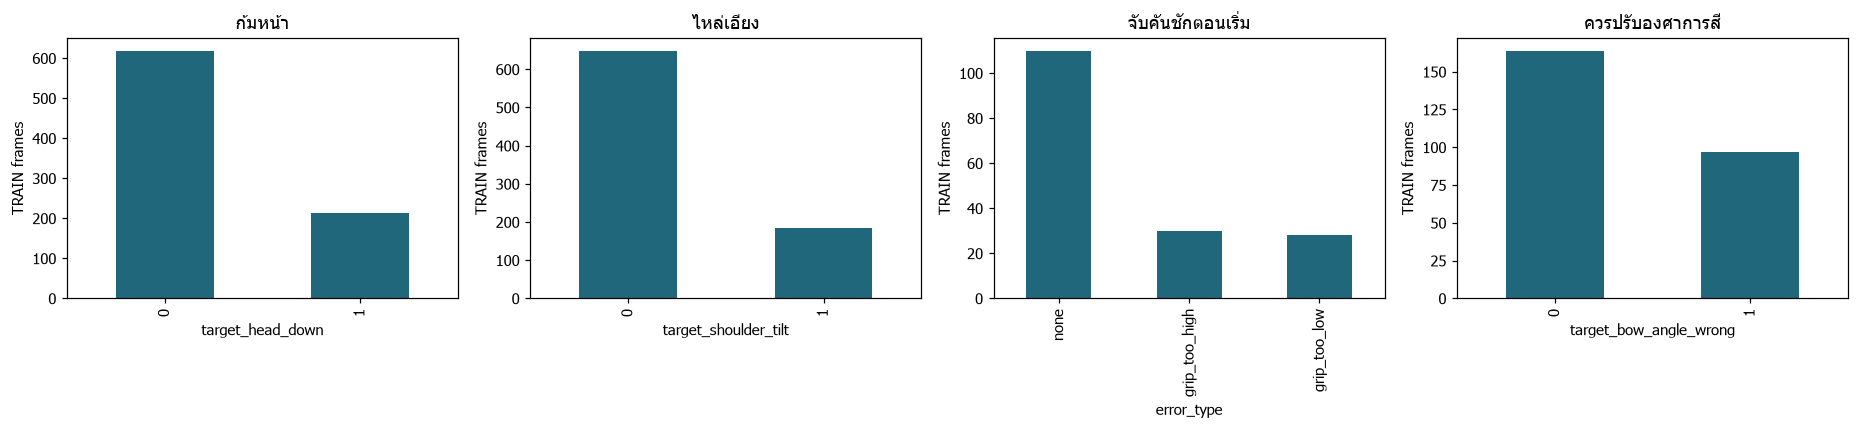

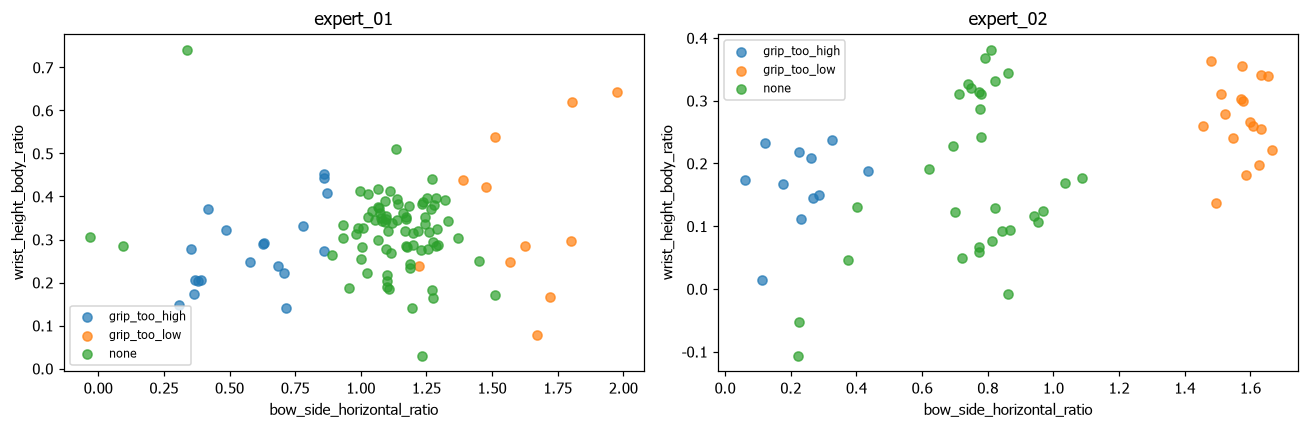

In [8]:
fig, axes = plt.subplots(1,4,figsize=(17,4))
for ax,(task,spec) in zip(axes,ce.TASKS.items()):
    train_data[task][spec['target']].astype(str).value_counts().reindex(spec['labels'],fill_value=0).plot.bar(ax=ax,color='#21677c')
    ax.set(title=spec['title'],ylabel='TRAIN frames')
fig.tight_layout(); fig.savefig(REPORT/'train_labels.png'); plt.show()
grip = train_data['initial_grip']
fig,axes = plt.subplots(1,2,figsize=(12,4))
for ax,(expert,df) in zip(axes,grip.groupby('expert')):
    for label,g in df.groupby('error_type'):
        ax.scatter(g.bow_side_horizontal_ratio,g.wrist_height_body_ratio,label=label,alpha=.7)
    ax.set(title=expert,xlabel='bow_side_horizontal_ratio',ylabel='wrist_height_body_ratio'); ax.legend(fontsize=8)
fig.tight_layout(); fig.savefig(REPORT/'grip_features_by_expert.png'); plt.show()

## 4.1 · เข้าใจน้ำหนักที่ใช้ fit
`clip_equal`: น้ำหนักแต่ละเฟรม = 1 / จำนวนเฟรมของคลิปนั้น แล้วปรับค่าเฉลี่ยให้เป็น 1
`clip_class_balanced`: เริ่มจากน้ำหนักเท่ากันต่อคลิป แล้วปรับให้น้ำหนักรวมแต่ละคลาสเท่ากัน
คำนวณน้ำหนักใหม่จากข้อมูลในแต่ละ fold เท่านั้น และเปรียบเทียบสองโหมดด้วย CV

In [9]:
example = train_data['initial_grip'].copy()
example['fit_weight'] = ce.fitting_weights(example,'error_type','clip_equal')
display(example[['clip_id','error_type','fit_weight']].head(8))
print('Equal clip totals:')
display(example.groupby('clip_id').fit_weight.sum().head())

,clip_id,error_type,fit_weight
0,expert_01/bow_hold/E01_BH_grip_too_high_S01_T01.mp4.mp4,grip_too_high,1.3125
1,expert_01/bow_hold/E01_BH_grip_too_high_S01_T01.mp4.mp4,grip_too_high,1.3125
2,expert_01/bow_hold/E01_BH_grip_too_high_S01_T01.mp4.mp4,grip_too_high,1.3125
3,expert_01/bow_hold/E01_BH_grip_too_high_S01_T01.mp4.mp4,grip_too_high,1.3125
4,expert_01/bow_hold/E01_BH_grip_too_high_S01_T04.mp4.mp4,grip_too_high,0.7500
5,expert_01/bow_hold/E01_BH_grip_too_high_S01_T04.mp4.mp4,grip_too_high,0.7500
6,expert_01/bow_hold/E01_BH_grip_too_high_S01_T04.mp4.mp4,grip_too_high,0.7500
7,expert_01/bow_hold/E01_BH_grip_too_high_S01_T04.mp4.mp4,grip_too_high,0.7500


Equal clip totals:


clip_id
expert_01/bow_hold/E01_BH_grip_too_high_S01_T01.mp4.mp4    5.25
expert_01/bow_hold/E01_BH_grip_too_high_S01_T04.mp4.mp4    5.25
expert_01/bow_hold/E01_BH_grip_too_high_S01_T05.mp4.mp4    5.25
expert_01/bow_hold/E01_BH_grip_too_low_S01_T01.mp4.mp4     5.25
expert_01/bow_hold/E01_BH_grip_too_low_S01_T04.mp4.mp4     5.25
Name: fit_weight, dtype: float64

## 4.2 · สร้าง Cross-validation ที่แยกทั้งคลิป
StratifiedGroupKFold 3 folds ใช้ `clip_id` เป็นกลุ่ม
แต่ละ fold ต้องมีทุกคลาสทั้งฝั่งฝึกและฝั่งตรวจ และไม่มีคลิปเดียวกันอยู่สองฝั่ง
ตาราง fold เก็บไว้เพื่อให้ตรวจสอบย้อนกลับได้

In [10]:
fold_indices = {task: ce.build_folds(df,task,CV_FOLDS,SEED) for task,df in train_data.items()}
fold_record, fold_rows = {}, []
for task,folds in fold_indices.items():
    df = train_data[task]
    fold_record[task] = []
    for number,(fit,held) in enumerate(folds,1):
        fit_clips = sorted(df.iloc[fit].clip_id.unique())
        held_clips = sorted(df.iloc[held].clip_id.unique())
        fold_record[task].append(dict(fold=number,fit_clips=fit_clips,held_clips=held_clips))
        fold_rows.append(dict(task=task,fold=number,fit_frames=len(fit),held_frames=len(held),fit_clips=len(fit_clips),held_clips=len(held_clips)))
ce.save_json(REPORT/'cv_folds.json',fold_record)
display(pd.DataFrame(fold_rows))

,task,fold,fit_frames,held_frames,fit_clips,held_clips
0,head_down,1,554,279,14,7
1,head_down,2,556,277,14,7
2,head_down,3,556,277,14,7
3,shoulder_tilt,1,557,276,14,7
4,shoulder_tilt,2,557,276,14,7
5,shoulder_tilt,3,552,281,14,7
6,initial_grip,1,111,57,22,10
7,initial_grip,2,111,57,21,11
8,initial_grip,3,114,54,21,11
9,bow_error,1,176,85,20,13


## 4.3 · สร้างรายการค่าที่จะลอง
Decision Tree เรียนกฎแบ่งข้อมูลเป็นเงื่อนไข ส่วน Random Forest รวมเสียงจากหลายต้นไม้
ไม่ต้อง StandardScaler สำหรับสองอัลกอริทึมนี้

In [11]:
candidates = ce.candidate_grid(TREE_GRID,FOREST_GRID)
display(pd.DataFrame(candidates).head(8))
print('Configurations per feature set:', len(candidates))
print('Total configurations:', sum(len(s['features'])*len(candidates) for s in ce.TASKS.values()))

,family,params,weight_mode
0,decision_tree,"{'max_depth': 2, 'min_samples_leaf': 2}",clip_equal
1,decision_tree,"{'max_depth': 2, 'min_samples_leaf': 2}",clip_class_balanced
2,decision_tree,"{'max_depth': 2, 'min_samples_leaf': 5}",clip_equal
3,decision_tree,"{'max_depth': 2, 'min_samples_leaf': 5}",clip_class_balanced
4,decision_tree,"{'max_depth': 2, 'min_samples_leaf': 10}",clip_equal
5,decision_tree,"{'max_depth': 2, 'min_samples_leaf': 10}",clip_class_balanced
6,decision_tree,"{'max_depth': 3, 'min_samples_leaf': 2}",clip_equal
7,decision_tree,"{'max_depth': 3, 'min_samples_leaf': 2}",clip_class_balanced


Configurations per feature set: 48
Total configurations: 240


## 5 · ค้นค่าของงาน ก้มหน้า (`head_down`)
ทุกตัวเลือก fit บนส่วน TRAIN ของ fold แล้วทำนายส่วนที่กันไว้
รวมคำทำนาย out-of-fold เพื่อคำนวณ Macro F1 แบบคลิปมีน้ำหนักเท่ากัน
ดูคะแนน CV และความแปรปรวนระหว่าง fold ไม่ใช้คะแนน train อย่างเดียว
`ce.search_task` คือ loop fit/predict เดียวกันสำหรับทุกงาน อ่านโค้ดได้ใน `combined_experts.py`

,candidate_id,family,feature_set,weight_mode,parameters,cv_f1,cv_accuracy,fold_std
19,head_down_020,decision_tree,posture_10,clip_class_balanced,"{""max_depth"": 6, ""min_samples_leaf"": 2}",0.7995,0.8157,0.1006
45,head_down_046,random_forest,posture_10,clip_class_balanced,"{""max_depth"": null, ""max_features"": 1.0, ""min_samples_leaf"": 2, ""n_estimators"": 150}",0.7862,0.8139,0.0523
37,head_down_038,random_forest,posture_10,clip_class_balanced,"{""max_depth"": 6, ""max_features"": 1.0, ""min_samples_leaf"": 2, ""n_estimators"": 150}",0.7856,0.8114,0.0523
36,head_down_037,random_forest,posture_10,clip_equal,"{""max_depth"": 6, ""max_features"": 1.0, ""min_samples_leaf"": 2, ""n_estimators"": 150}",0.7796,0.8080,0.0735
38,head_down_039,random_forest,posture_10,clip_equal,"{""max_depth"": 6, ""max_features"": 1.0, ""min_samples_leaf"": 5, ""n_estimators"": 150}",0.7794,0.8095,0.0895
44,head_down_045,random_forest,posture_10,clip_equal,"{""max_depth"": null, ""max_features"": 1.0, ""min_samples_leaf"": 2, ""n_estimators"": 150}",0.7785,0.8076,0.0648
46,head_down_047,random_forest,posture_10,clip_equal,"{""max_depth"": null, ""max_features"": 1.0, ""min_samples_leaf"": 5, ""n_estimators"": 150}",0.7720,0.8027,0.0839
13,head_down_014,decision_tree,posture_10,clip_class_balanced,"{""max_depth"": 4, ""min_samples_leaf"": 2}",0.7697,0.7995,0.0714
18,head_down_019,decision_tree,posture_10,clip_equal,"{""max_depth"": 6, ""min_samples_leaf"": 2}",0.7687,0.7987,0.0885
23,head_down_024,decision_tree,posture_10,clip_class_balanced,"{""max_depth"": 6, ""min_samples_leaf"": 10}",0.7659,0.7926,0.0111


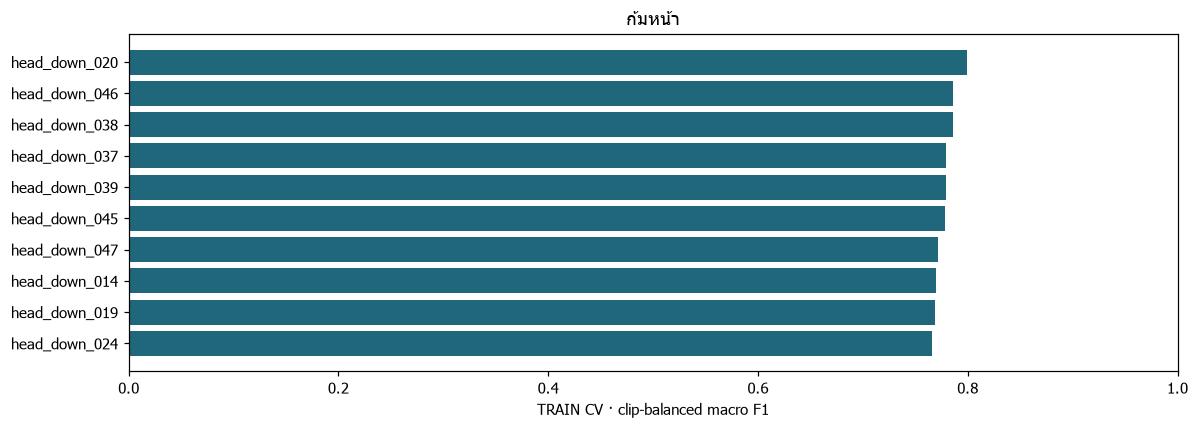

In [12]:
search_path = REPORT/'cv_head_down.json'
if not search_path.exists():
    trials = ce.search_task('head_down',train_data['head_down'],candidates,
                            fold_indices['head_down'],SEED,N_JOBS)
    ce.save_json(search_path,trials)
else:
    trials = ce.read_json(search_path)
cv_table = ce.trial_table(trials)
cv_table.to_csv(REPORT/'cv_head_down.csv',index=False,encoding='utf-8-sig')
display(cv_table.head(12).round(4))
fig,ax = plt.subplots(figsize=(11,4))
top = cv_table.head(10).iloc[::-1]
ax.barh(top.candidate_id,top.cv_f1,color='#21677c')
ax.set(xlim=(0,1),xlabel='TRAIN CV · clip-balanced macro F1',title='ก้มหน้า')
fig.tight_layout(); fig.savefig(REPORT/'cv_head_down.png'); plt.show()

## 5 · ค้นค่าของงาน ไหล่เอียง (`shoulder_tilt`)
ทุกตัวเลือก fit บนส่วน TRAIN ของ fold แล้วทำนายส่วนที่กันไว้
รวมคำทำนาย out-of-fold เพื่อคำนวณ Macro F1 แบบคลิปมีน้ำหนักเท่ากัน
ดูคะแนน CV และความแปรปรวนระหว่าง fold ไม่ใช้คะแนน train อย่างเดียว
`ce.search_task` คือ loop fit/predict เดียวกันสำหรับทุกงาน อ่านโค้ดได้ใน `combined_experts.py`

,candidate_id,family,feature_set,weight_mode,parameters,cv_f1,cv_accuracy,fold_std
5,shoulder_tilt_006,decision_tree,posture_10,clip_class_balanced,"{""max_depth"": 2, ""min_samples_leaf"": 10}",0.8199,0.8433,0.0866
10,shoulder_tilt_011,decision_tree,posture_10,clip_equal,"{""max_depth"": 3, ""min_samples_leaf"": 10}",0.7987,0.8214,0.0958
4,shoulder_tilt_005,decision_tree,posture_10,clip_equal,"{""max_depth"": 2, ""min_samples_leaf"": 10}",0.7949,0.8259,0.1178
29,shoulder_tilt_030,random_forest,posture_10,clip_class_balanced,"{""max_depth"": 3, ""max_features"": 1.0, ""min_samples_leaf"": 2, ""n_estimators"": 150}",0.7867,0.8208,0.1509
1,shoulder_tilt_002,decision_tree,posture_10,clip_class_balanced,"{""max_depth"": 2, ""min_samples_leaf"": 2}",0.7858,0.8086,0.0425
3,shoulder_tilt_004,decision_tree,posture_10,clip_class_balanced,"{""max_depth"": 2, ""min_samples_leaf"": 5}",0.7858,0.8086,0.0425
28,shoulder_tilt_029,random_forest,posture_10,clip_equal,"{""max_depth"": 3, ""max_features"": 1.0, ""min_samples_leaf"": 2, ""n_estimators"": 150}",0.7827,0.8243,0.1581
11,shoulder_tilt_012,decision_tree,posture_10,clip_class_balanced,"{""max_depth"": 3, ""min_samples_leaf"": 10}",0.7820,0.8041,0.0554
30,shoulder_tilt_031,random_forest,posture_10,clip_equal,"{""max_depth"": 3, ""max_features"": 1.0, ""min_samples_leaf"": 5, ""n_estimators"": 150}",0.7796,0.8167,0.1251
13,shoulder_tilt_014,decision_tree,posture_10,clip_class_balanced,"{""max_depth"": 4, ""min_samples_leaf"": 2}",0.7719,0.8072,0.1234


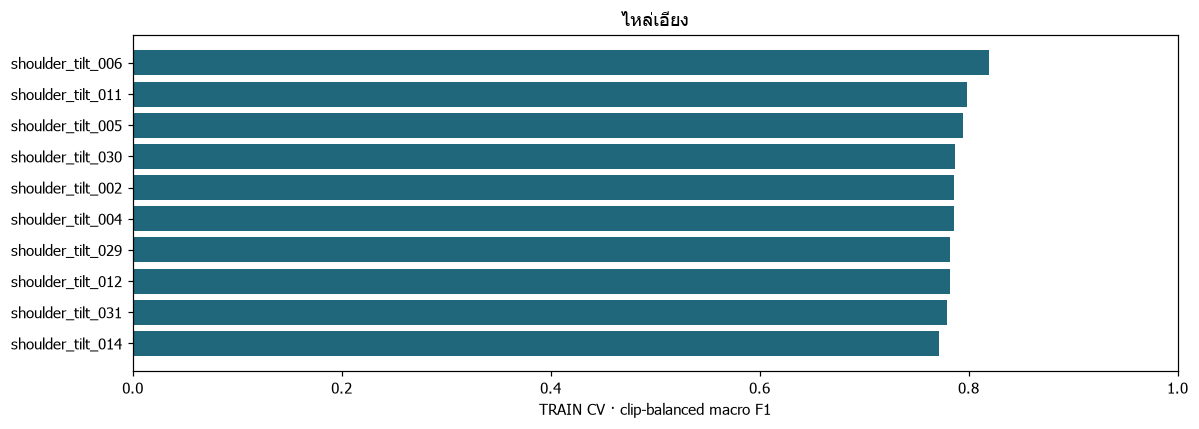

In [13]:
search_path = REPORT/'cv_shoulder_tilt.json'
if not search_path.exists():
    trials = ce.search_task('shoulder_tilt',train_data['shoulder_tilt'],candidates,
                            fold_indices['shoulder_tilt'],SEED,N_JOBS)
    ce.save_json(search_path,trials)
else:
    trials = ce.read_json(search_path)
cv_table = ce.trial_table(trials)
cv_table.to_csv(REPORT/'cv_shoulder_tilt.csv',index=False,encoding='utf-8-sig')
display(cv_table.head(12).round(4))
fig,ax = plt.subplots(figsize=(11,4))
top = cv_table.head(10).iloc[::-1]
ax.barh(top.candidate_id,top.cv_f1,color='#21677c')
ax.set(xlim=(0,1),xlabel='TRAIN CV · clip-balanced macro F1',title='ไหล่เอียง')
fig.tight_layout(); fig.savefig(REPORT/'cv_shoulder_tilt.png'); plt.show()

## 5 · ค้นค่าของงาน จับคันชักตอนเริ่ม (`initial_grip`)
ทุกตัวเลือก fit บนส่วน TRAIN ของ fold แล้วทำนายส่วนที่กันไว้
รวมคำทำนาย out-of-fold เพื่อคำนวณ Macro F1 แบบคลิปมีน้ำหนักเท่ากัน
ดูคะแนน CV และความแปรปรวนระหว่าง fold ไม่ใช้คะแนน train อย่างเดียว
`ce.search_task` คือ loop fit/predict เดียวกันสำหรับทุกงาน อ่านโค้ดได้ใน `combined_experts.py`

,candidate_id,family,feature_set,weight_mode,parameters,cv_f1,cv_accuracy,fold_std
39,initial_grip_040,random_forest,body_2,clip_class_balanced,"{""max_depth"": 6, ""max_features"": 1.0, ""min_samples_leaf"": 5, ""n_estimators"": 150}",0.7942,0.8134,0.0869
47,initial_grip_048,random_forest,body_2,clip_class_balanced,"{""max_depth"": null, ""max_features"": 1.0, ""min_samples_leaf"": 5, ""n_estimators"": 150}",0.7942,0.8134,0.0869
87,initial_grip_088,random_forest,body_4,clip_class_balanced,"{""max_depth"": 6, ""max_features"": 1.0, ""min_samples_leaf"": 5, ""n_estimators"": 150}",0.7942,0.8134,0.0869
95,initial_grip_096,random_forest,body_4,clip_class_balanced,"{""max_depth"": null, ""max_features"": 1.0, ""min_samples_leaf"": 5, ""n_estimators"": 150}",0.7942,0.8134,0.0869
29,initial_grip_030,random_forest,body_2,clip_class_balanced,"{""max_depth"": 3, ""max_features"": 1.0, ""min_samples_leaf"": 2, ""n_estimators"": 150}",0.7937,0.8160,0.1097
31,initial_grip_032,random_forest,body_2,clip_class_balanced,"{""max_depth"": 3, ""max_features"": 1.0, ""min_samples_leaf"": 5, ""n_estimators"": 150}",0.7914,0.8072,0.0814
79,initial_grip_080,random_forest,body_4,clip_class_balanced,"{""max_depth"": 3, ""max_features"": 1.0, ""min_samples_leaf"": 5, ""n_estimators"": 150}",0.7914,0.8072,0.0814
75,initial_grip_076,random_forest,body_4,clip_class_balanced,"{""max_depth"": 3, ""max_features"": ""sqrt"", ""min_samples_leaf"": 5, ""n_estimators"": 150}",0.7849,0.7994,0.0776
27,initial_grip_028,random_forest,body_2,clip_class_balanced,"{""max_depth"": 3, ""max_features"": ""sqrt"", ""min_samples_leaf"": 5, ""n_estimators"": 150}",0.7833,0.8028,0.1119
0,initial_grip_001,decision_tree,body_2,clip_equal,"{""max_depth"": 2, ""min_samples_leaf"": 2}",0.7831,0.8046,0.0743


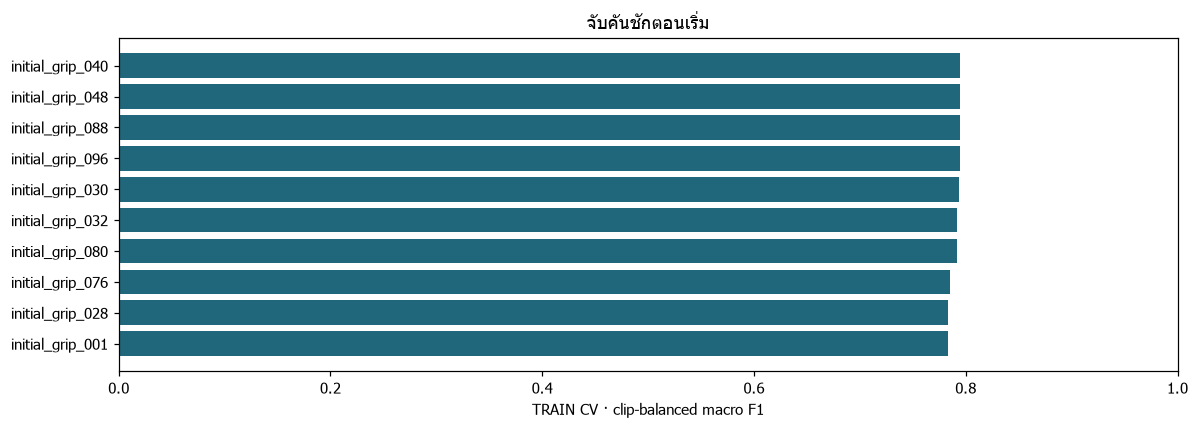

In [14]:
search_path = REPORT/'cv_initial_grip.json'
if not search_path.exists():
    trials = ce.search_task('initial_grip',train_data['initial_grip'],candidates,
                            fold_indices['initial_grip'],SEED,N_JOBS)
    ce.save_json(search_path,trials)
else:
    trials = ce.read_json(search_path)
cv_table = ce.trial_table(trials)
cv_table.to_csv(REPORT/'cv_initial_grip.csv',index=False,encoding='utf-8-sig')
display(cv_table.head(12).round(4))
fig,ax = plt.subplots(figsize=(11,4))
top = cv_table.head(10).iloc[::-1]
ax.barh(top.candidate_id,top.cv_f1,color='#21677c')
ax.set(xlim=(0,1),xlabel='TRAIN CV · clip-balanced macro F1',title='จับคันชักตอนเริ่ม')
fig.tight_layout(); fig.savefig(REPORT/'cv_initial_grip.png'); plt.show()

## 5 · ค้นค่าของงาน ควรปรับองศาการสี (`bow_error`)
ทุกตัวเลือก fit บนส่วน TRAIN ของ fold แล้วทำนายส่วนที่กันไว้
รวมคำทำนาย out-of-fold เพื่อคำนวณ Macro F1 แบบคลิปมีน้ำหนักเท่ากัน
ดูคะแนน CV และความแปรปรวนระหว่าง fold ไม่ใช้คะแนน train อย่างเดียว
`ce.search_task` คือ loop fit/predict เดียวกันสำหรับทุกงาน อ่านโค้ดได้ใน `combined_experts.py`

,candidate_id,family,feature_set,weight_mode,parameters,cv_f1,cv_accuracy,fold_std
10,bow_error_011,decision_tree,body_4,clip_equal,"{""max_depth"": 3, ""min_samples_leaf"": 10}",0.7173,0.8771,0.0776
16,bow_error_017,decision_tree,body_4,clip_equal,"{""max_depth"": 4, ""min_samples_leaf"": 10}",0.7115,0.8710,0.0801
22,bow_error_023,decision_tree,body_4,clip_equal,"{""max_depth"": 6, ""min_samples_leaf"": 10}",0.7115,0.8710,0.0801
12,bow_error_013,decision_tree,body_4,clip_equal,"{""max_depth"": 4, ""min_samples_leaf"": 2}",0.7003,0.8704,0.0739
6,bow_error_007,decision_tree,body_4,clip_equal,"{""max_depth"": 3, ""min_samples_leaf"": 2}",0.6912,0.8733,0.0909
8,bow_error_009,decision_tree,body_4,clip_equal,"{""max_depth"": 3, ""min_samples_leaf"": 5}",0.6772,0.8654,0.0945
30,bow_error_031,random_forest,body_4,clip_equal,"{""max_depth"": 3, ""max_features"": 1.0, ""min_samples_leaf"": 5, ""n_estimators"": 150}",0.6692,0.8675,0.0675
38,bow_error_039,random_forest,body_4,clip_equal,"{""max_depth"": 6, ""max_features"": 1.0, ""min_samples_leaf"": 5, ""n_estimators"": 150}",0.6692,0.8675,0.0675
46,bow_error_047,random_forest,body_4,clip_equal,"{""max_depth"": null, ""max_features"": 1.0, ""min_samples_leaf"": 5, ""n_estimators"": 150}",0.6692,0.8675,0.0675
34,bow_error_035,random_forest,body_4,clip_equal,"{""max_depth"": 6, ""max_features"": ""sqrt"", ""min_samples_leaf"": 5, ""n_estimators"": 150}",0.6635,0.8660,0.0772


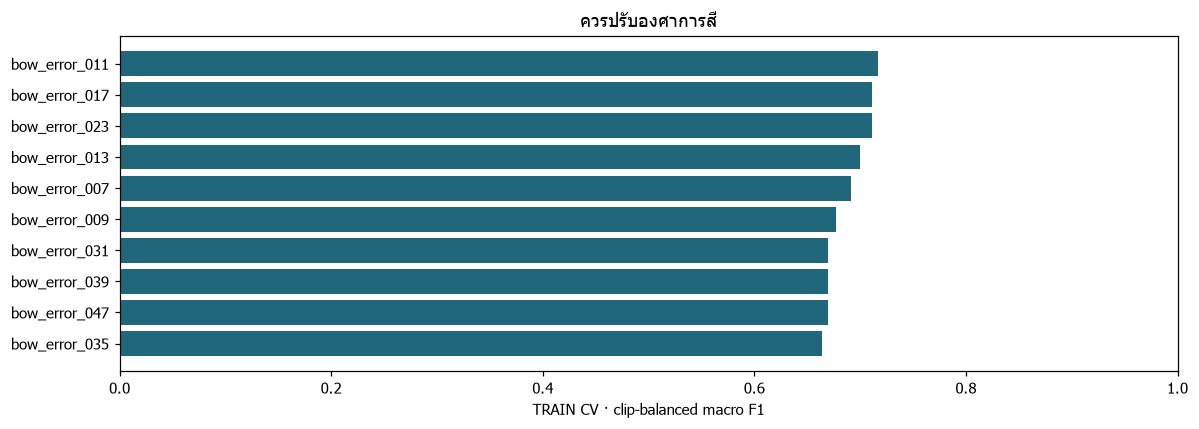

In [15]:
search_path = REPORT/'cv_bow_error.json'
if not search_path.exists():
    trials = ce.search_task('bow_error',train_data['bow_error'],candidates,
                            fold_indices['bow_error'],SEED,N_JOBS)
    ce.save_json(search_path,trials)
else:
    trials = ce.read_json(search_path)
cv_table = ce.trial_table(trials)
cv_table.to_csv(REPORT/'cv_bow_error.csv',index=False,encoding='utf-8-sig')
display(cv_table.head(12).round(4))
fig,ax = plt.subplots(figsize=(11,4))
top = cv_table.head(10).iloc[::-1]
ax.barh(top.candidate_id,top.cv_f1,color='#21677c')
ax.set(xlim=(0,1),xlabel='TRAIN CV · clip-balanced macro F1',title='ควรปรับองศาการสี')
fig.tight_layout(); fig.savefig(REPORT/'cv_bow_error.png'); plt.show()

## 6.1 · Shortlist และเลือกด้วย Validation
ให้เฉพาะตัวที่ได้ TRAIN CV ดีที่สุดของแต่ละครอบครัวเข้ารอบ: 1 Tree และ 1 Forest ต่อหนึ่งงาน
เลือกด้วย VAL clip-balanced macro F1; ถ้าเท่ากันดู CV และเลือก Tree เมื่อยังเท่ากัน
มี Dummy ที่ทายคลาสส่วนใหญ่เป็นฐานเปรียบเทียบ
รายละเอียด confusion matrix/รายคนอยู่เล่ม 02 และไม่มี TEST ในการเลือกนี้

In [16]:
selection_path = REPORT/'selection.json'
if not selection_path.exists():
    selection = {}
    for task in ce.TASKS:
        trials = ce.read_json(REPORT/f'cv_{task}.json')
        finalists, fitted, best, dummy, baseline = ce.validate_shortlist(
            task,train_data[task],val_data[task],trials,SEED,N_JOBS)
        candidate_dir = MODEL_DIR/'validation/candidates'
        candidate_dir.mkdir(exist_ok=True)
        for finalist in finalists:
            ce.save_bundle(task,fitted[finalist['candidate_id']],finalist,
                           train_data[task],['train'],candidate_dir/f"{finalist['candidate_id']}.joblib",RUN)
        ce.save_bundle(task,fitted[best['candidate_id']],best,train_data[task],
                       ['train'],MODEL_DIR/'validation'/f'{task}.joblib',RUN)
        dummy_features = next(iter(ce.TASKS[task]['features'].values()))
        joblib.dump(dict(model=dummy,feature_columns=dummy_features),MODEL_DIR/'validation'/f'{task}_dummy.joblib')
        selection[task] = dict(selected=best,finalists=finalists,dummy_val=baseline)
    ce.save_json(selection_path,selection)
else:
    selection = ce.read_json(selection_path)
validation_rows = []
for task,entry in selection.items():
    for item in entry['finalists']:
        validation_rows.append(dict(task=task,family=item['family'],features=item['feature_set'],
            parameters=json.dumps(item['params']),weight_mode=item['weight_mode'],
            train_f1=item['train']['clip_balanced_macro_f1'],cv_f1=item['cv']['clip_balanced_macro_f1'],
            val_f1=item['val']['clip_balanced_macro_f1'],
            selected=item['candidate_id']==entry['selected']['candidate_id']))
validation_table = pd.DataFrame(validation_rows)
display(validation_table.round(4))
validation_table.to_csv(REPORT/'validation_shortlist.csv',index=False,encoding='utf-8-sig')

,task,family,features,parameters,weight_mode,train_f1,cv_f1,val_f1,selected
0,head_down,decision_tree,posture_10,"{""max_depth"": 6, ""min_samples_leaf"": 2}",clip_class_balanced,0.9756,0.7995,0.6687,False
1,head_down,random_forest,posture_10,"{""max_depth"": null, ""max_features"": 1.0, ""min_samples_leaf"": 2, ""n_estimators"": 150}",clip_class_balanced,0.9908,0.7862,0.7072,True
2,shoulder_tilt,decision_tree,posture_10,"{""max_depth"": 2, ""min_samples_leaf"": 10}",clip_class_balanced,0.8884,0.8199,0.6542,False
3,shoulder_tilt,random_forest,posture_10,"{""max_depth"": 3, ""max_features"": 1.0, ""min_samples_leaf"": 2, ""n_estimators"": 150}",clip_class_balanced,0.9059,0.7867,0.7494,True
4,initial_grip,decision_tree,body_2,"{""max_depth"": 2, ""min_samples_leaf"": 10}",clip_equal,0.8606,0.7831,0.7320,False
5,initial_grip,random_forest,body_2,"{""max_depth"": 6, ""max_features"": 1.0, ""min_samples_leaf"": 5, ""n_estimators"": 150}",clip_class_balanced,0.8782,0.7942,0.7320,True
6,bow_error,decision_tree,body_4,"{""max_depth"": 3, ""min_samples_leaf"": 10}",clip_equal,0.7593,0.7173,0.8274,True
7,bow_error,random_forest,body_4,"{""max_depth"": 3, ""max_features"": 1.0, ""min_samples_leaf"": 5, ""n_estimators"": 150}",clip_equal,0.7690,0.6692,0.7924,False


## 6.2 · ล็อกตัวเลือกก่อนเปิด TEST
บันทึกชื่อผู้ชนะ พารามิเตอร์ feature และ SHA256 ของ selection
ต่อจากนี้ TEST ใช้รายงานผลเท่านั้น หากเห็น test แล้วแก้ค่าและประเมินชุดเดิมซ้ำ ผลจะไม่ใช่ test ที่สดใหม่

In [17]:
lock_path = REPORT/'selection_lock.json'
selection_hash = ce.sha256(selection_path)
if lock_path.exists():
    assert ce.read_json(lock_path)['selection_sha256'] == selection_hash
else:
    ce.save_json(lock_path,dict(run=RUN,selection_sha256=selection_hash,
        locked_at=ce.datetime.now(ce.ZoneInfo('Asia/Bangkok')).isoformat(),test_used_for_selection=False,
        winners={task:entry['selected']['candidate_id'] for task,entry in selection.items()}))
display(pd.DataFrame([dict(task=task,selected=e['selected']['candidate_id'],
    family=e['selected']['family'],features=e['selected']['feature_set'],
    params=json.dumps(e['selected']['params']),weight_mode=e['selected']['weight_mode'])
    for task,e in selection.items()]))

,task,selected,family,features,params,weight_mode
0,head_down,head_down_046,random_forest,posture_10,"{""max_depth"": null, ""max_features"": 1.0, ""min_samples_leaf"": 2, ""n_estimators"": 150}",clip_class_balanced
1,shoulder_tilt,shoulder_tilt_030,random_forest,posture_10,"{""max_depth"": 3, ""max_features"": 1.0, ""min_samples_leaf"": 2, ""n_estimators"": 150}",clip_class_balanced
2,initial_grip,initial_grip_040,random_forest,body_2,"{""max_depth"": 6, ""max_features"": 1.0, ""min_samples_leaf"": 5, ""n_estimators"": 150}",clip_class_balanced
3,bow_error,bow_error_011,decision_tree,body_4,"{""max_depth"": 3, ""min_samples_leaf"": 10}",clip_equal


## 7.1 · Fit รุ่นสุดท้ายด้วย TRAIN + VAL
หลังเลือกค่าจบแล้ว รวม TRAIN+VAL เพื่อให้รุ่นสุดท้ายได้เรียนจากข้อมูลมากขึ้น
เก็บรุ่นที่ fit TRAIN อย่างเดียวไว้สำหรับรายงาน VAL แยกต่างหาก
ห้ามใช้รุ่นสุดท้ายมารายงาน VAL ว่าเป็นข้อมูลที่โมเดลไม่เคยเห็น

In [18]:
final_bundles = {}
for task,entry in selection.items():
    path = MODEL_DIR/'final'/f'{task}.joblib'
    if not path.exists():
        fit_df = pd.concat([train_data[task],val_data[task]],ignore_index=True)
        best = entry['selected']
        model = ce.fit_candidate(task,fit_df,best,SEED,N_JOBS)
        ce.save_bundle(task,model,best,fit_df,['train','val'],path,RUN)
    final_bundles[task] = joblib.load(path)
display(pd.DataFrame([dict(task=task,fit_splits=b['fit_splits'],
    frames=b['fit_frames'],clips=b['fit_clips'],features=b['feature_columns'])
    for task,b in final_bundles.items()]))

,task,fit_splits,frames,clips,features
0,head_down,"[train, val]",1091,28,"[shoulder_tilt_deg, head_tilt_deg, torso_tilt_deg, head_height_ratio, head_side_offset_ratio, no..."
1,shoulder_tilt,"[train, val]",1091,28,"[shoulder_tilt_deg, head_tilt_deg, torso_tilt_deg, head_height_ratio, head_side_offset_ratio, no..."
2,initial_grip,"[train, val]",220,43,"[bow_side_horizontal_ratio, wrist_height_body_ratio]"
3,bow_error,"[train, val]",344,44,"[bow_side_horizontal_ratio, bow_side_perpendicular_ratio, wrist_height_screen_ratio, wrist_heigh..."


## 7.2 · ตรวจ Feature importance
เป็นความสำคัญจากการแบ่งกิ่งของโมเดล ไม่ใช่หลักฐานเหตุและผล
Feature ที่คล้ายกันอาจแบ่งความสำคัญกัน และค่าความลึก z เป็นเพียงการประมาณ

,feature,importance
5,nose_below_ears_ratio,0.4504
1,head_tilt_deg,0.1719
0,shoulder_tilt_deg,0.1494
3,head_height_ratio,0.0770
4,head_side_offset_ratio,0.0371
8,nose_depth_vs_shoulders_ratio,0.0309
6,torso_length_ratio,0.0273
2,torso_tilt_deg,0.0259
9,shoulder_depth_vs_hips_ratio,0.0167
7,hip_width_ratio,0.0133


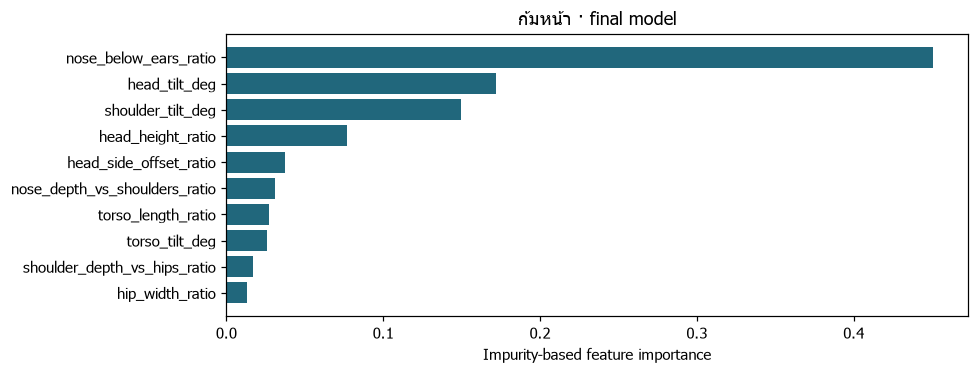

In [19]:
bundle = final_bundles['head_down']
fig,importance = ce.plot_importance(bundle,'ก้มหน้า · final model')
display(importance.round(4))
fig.savefig(REPORT/'importance_head_down.png'); plt.show()
importance.to_csv(REPORT/'importance_head_down.csv',index=False,encoding='utf-8-sig')

,feature,importance
4,head_side_offset_ratio,0.5306
3,head_height_ratio,0.1805
5,nose_below_ears_ratio,0.1197
1,head_tilt_deg,0.0711
2,torso_tilt_deg,0.0413
0,shoulder_tilt_deg,0.0363
8,nose_depth_vs_shoulders_ratio,0.0088
7,hip_width_ratio,0.0078
9,shoulder_depth_vs_hips_ratio,0.0021
6,torso_length_ratio,0.0017


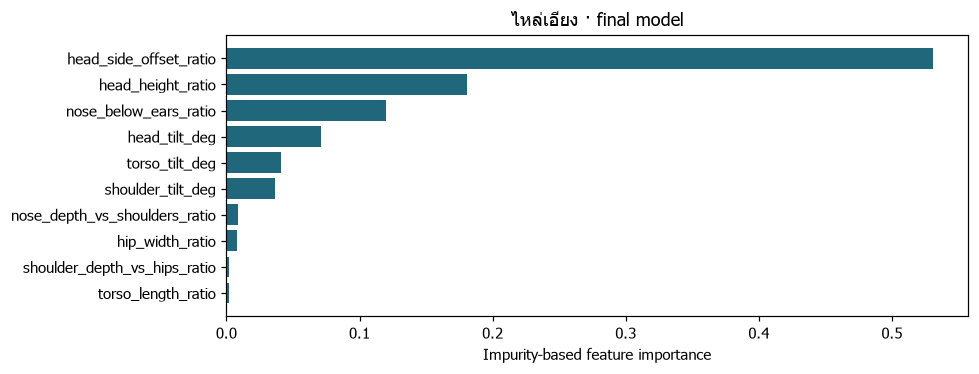

In [20]:
bundle = final_bundles['shoulder_tilt']
fig,importance = ce.plot_importance(bundle,'ไหล่เอียง · final model')
display(importance.round(4))
fig.savefig(REPORT/'importance_shoulder_tilt.png'); plt.show()
importance.to_csv(REPORT/'importance_shoulder_tilt.csv',index=False,encoding='utf-8-sig')

,feature,importance
0,bow_side_horizontal_ratio,0.917
1,wrist_height_body_ratio,0.083


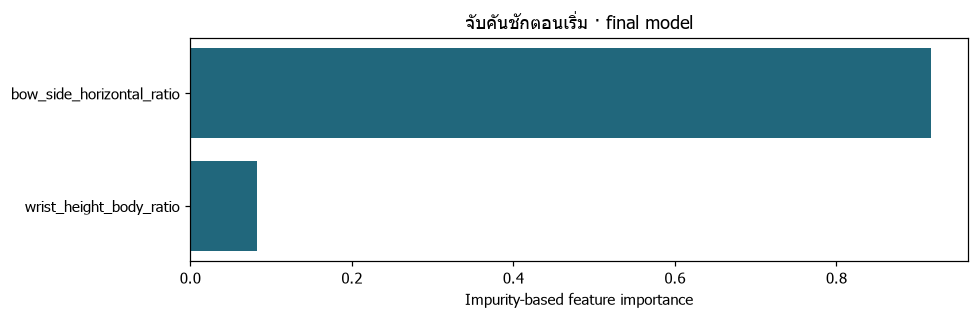

In [21]:
bundle = final_bundles['initial_grip']
fig,importance = ce.plot_importance(bundle,'จับคันชักตอนเริ่ม · final model')
display(importance.round(4))
fig.savefig(REPORT/'importance_initial_grip.png'); plt.show()
importance.to_csv(REPORT/'importance_initial_grip.csv',index=False,encoding='utf-8-sig')

,feature,importance
3,wrist_height_body_ratio,0.7840
0,bow_side_horizontal_ratio,0.1110
1,bow_side_perpendicular_ratio,0.0948
2,wrist_height_screen_ratio,0.0102


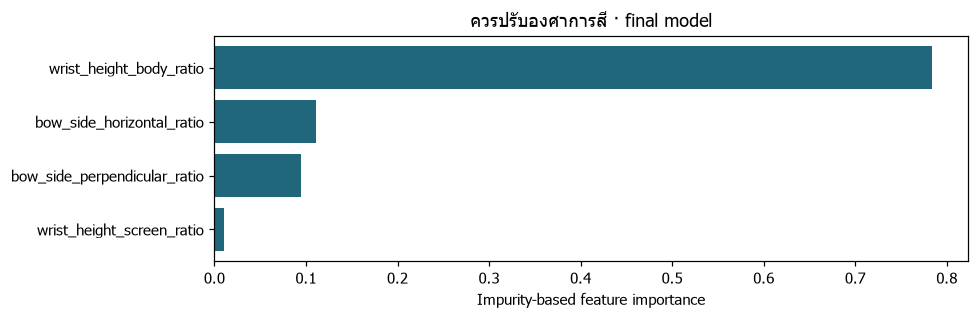

In [22]:
bundle = final_bundles['bow_error']
fig,importance = ce.plot_importance(bundle,'ควรปรับองศาการสี · final model')
display(importance.round(4))
fig.savefig(REPORT/'importance_bow_error.png'); plt.show()
importance.to_csv(REPORT/'importance_bow_error.csv',index=False,encoding='utf-8-sig')

## 7.3 · อ่านต้นไม้และกฎ
แต่ละ node แสดงเงื่อนไข feature และค่าตัด หากเป็น Forest แสดงต้นแรกเป็นตัวอย่างเท่านั้น
แสดงต้นไม้ถึงระดับ 3 เพื่ออ่านง่าย กฎเต็มของ Decision Tree บันทึกเป็นไฟล์ข้อความ
ก้มหน้าและไหล่เอียงมีต้นไม้/Forest คนละชุด ไม่บังคับให้เลือกอาการเดียว

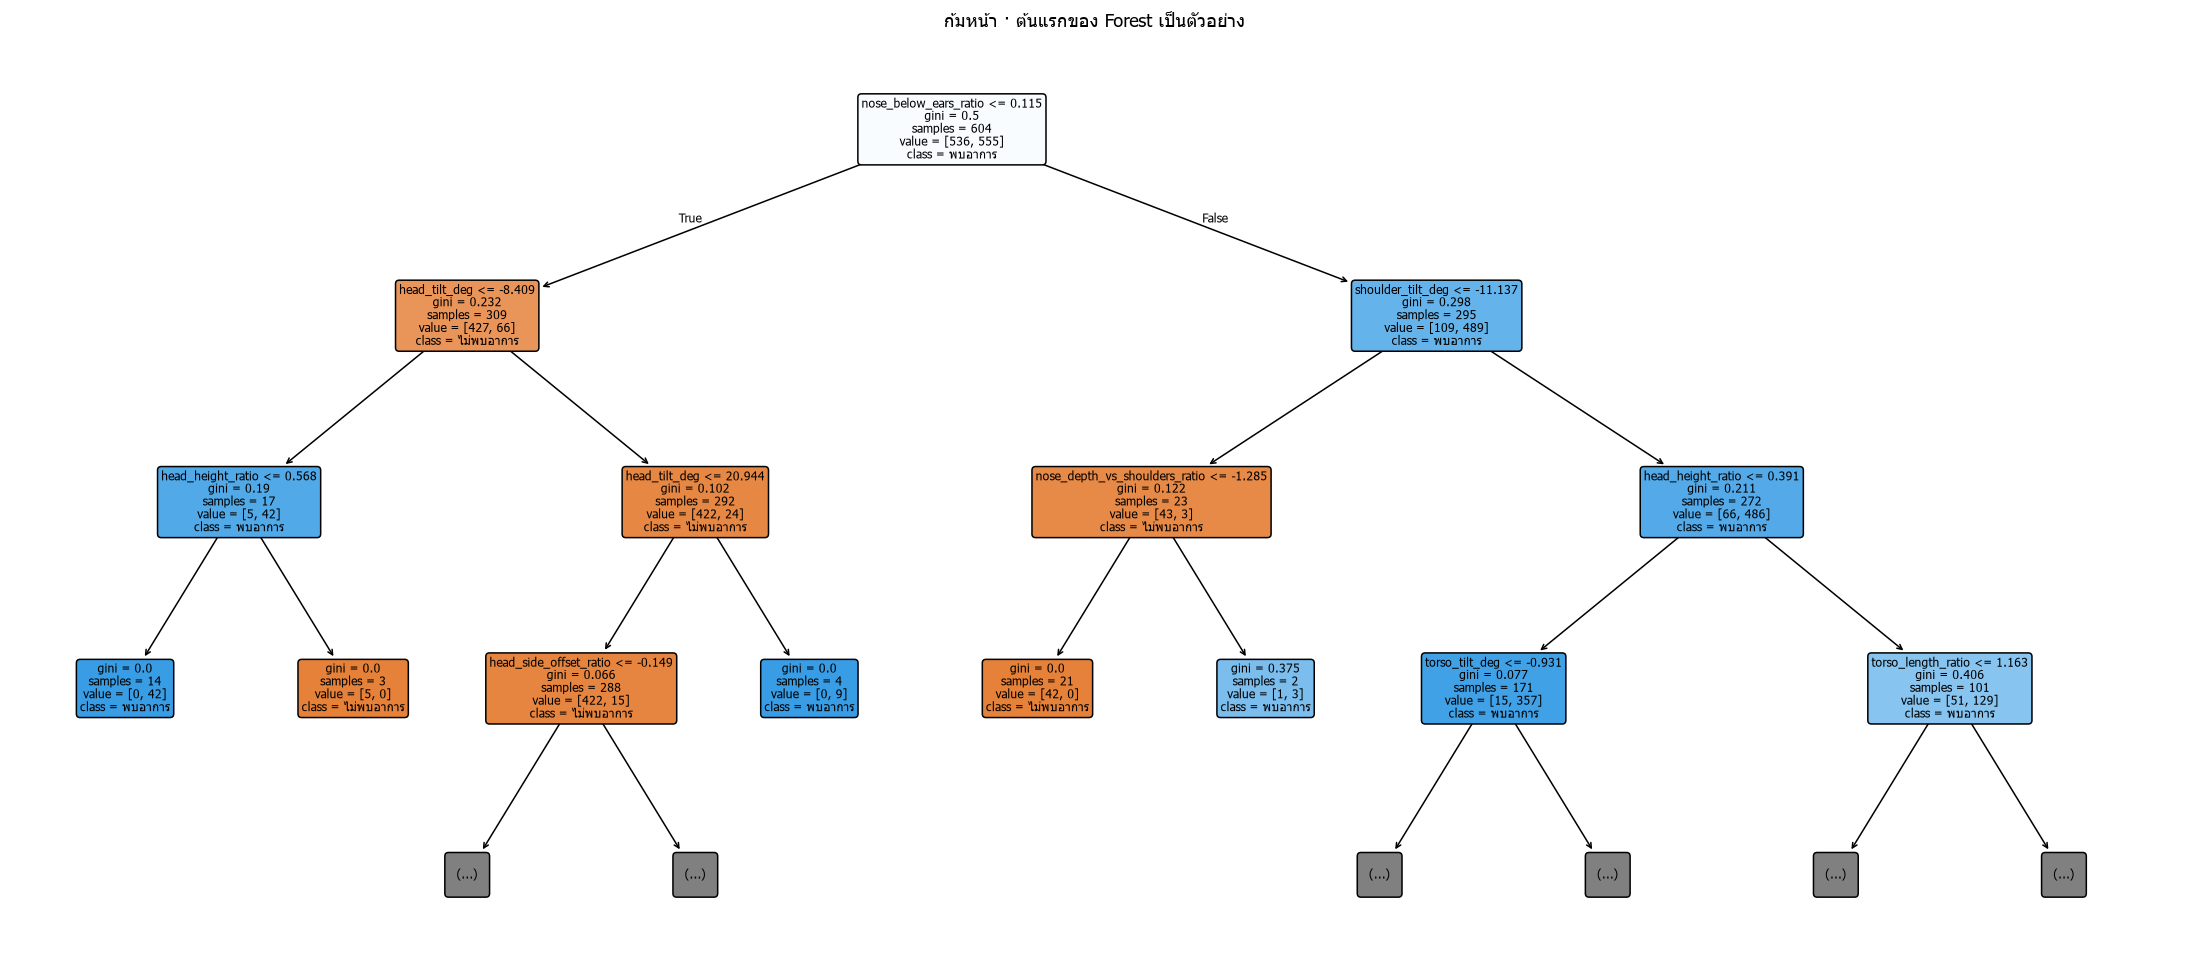

In [23]:
bundle = final_bundles['head_down']
fig = ce.plot_model_tree(bundle,'ก้มหน้า')
fig.savefig(REPORT/'tree_head_down.png',dpi=130); plt.show()
ce.save_tree_rules(bundle,REPORT/'rules_head_down.txt')

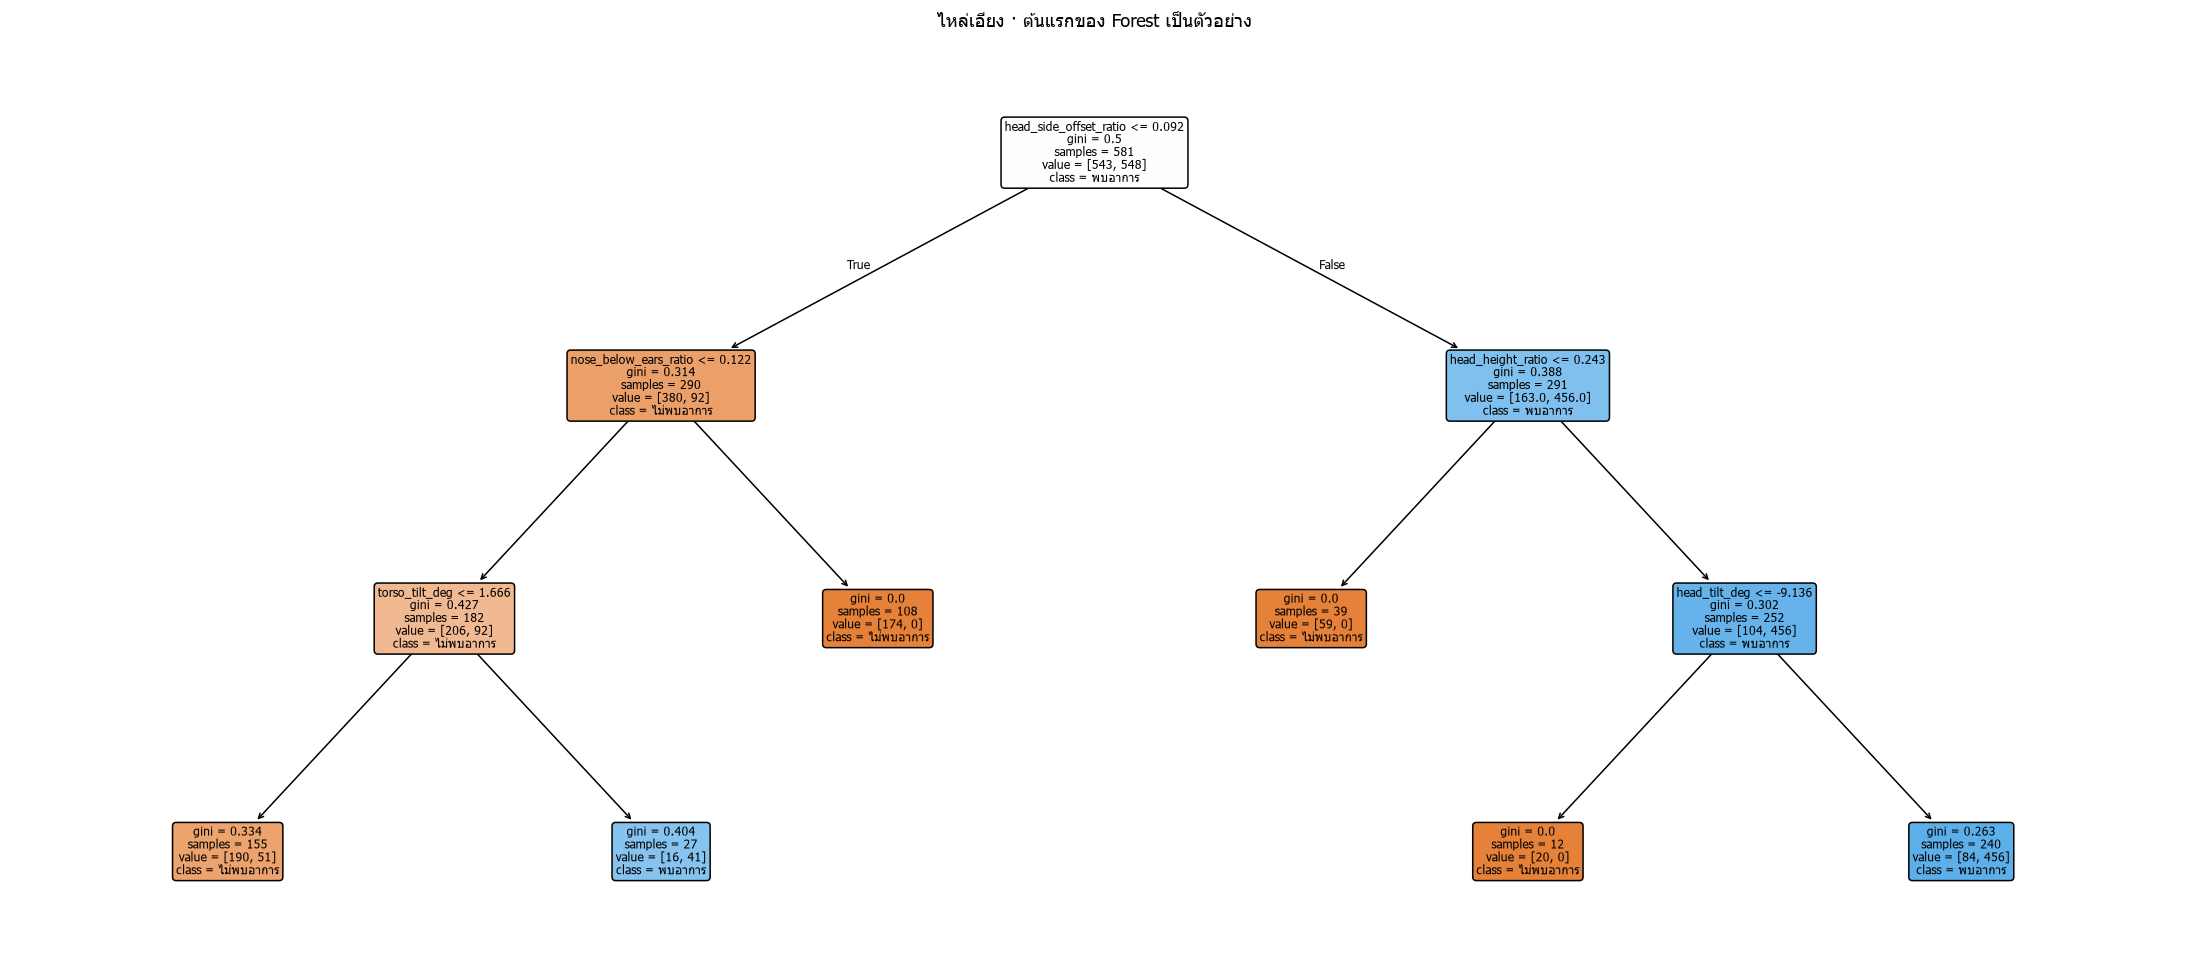

In [24]:
bundle = final_bundles['shoulder_tilt']
fig = ce.plot_model_tree(bundle,'ไหล่เอียง')
fig.savefig(REPORT/'tree_shoulder_tilt.png',dpi=130); plt.show()
ce.save_tree_rules(bundle,REPORT/'rules_shoulder_tilt.txt')

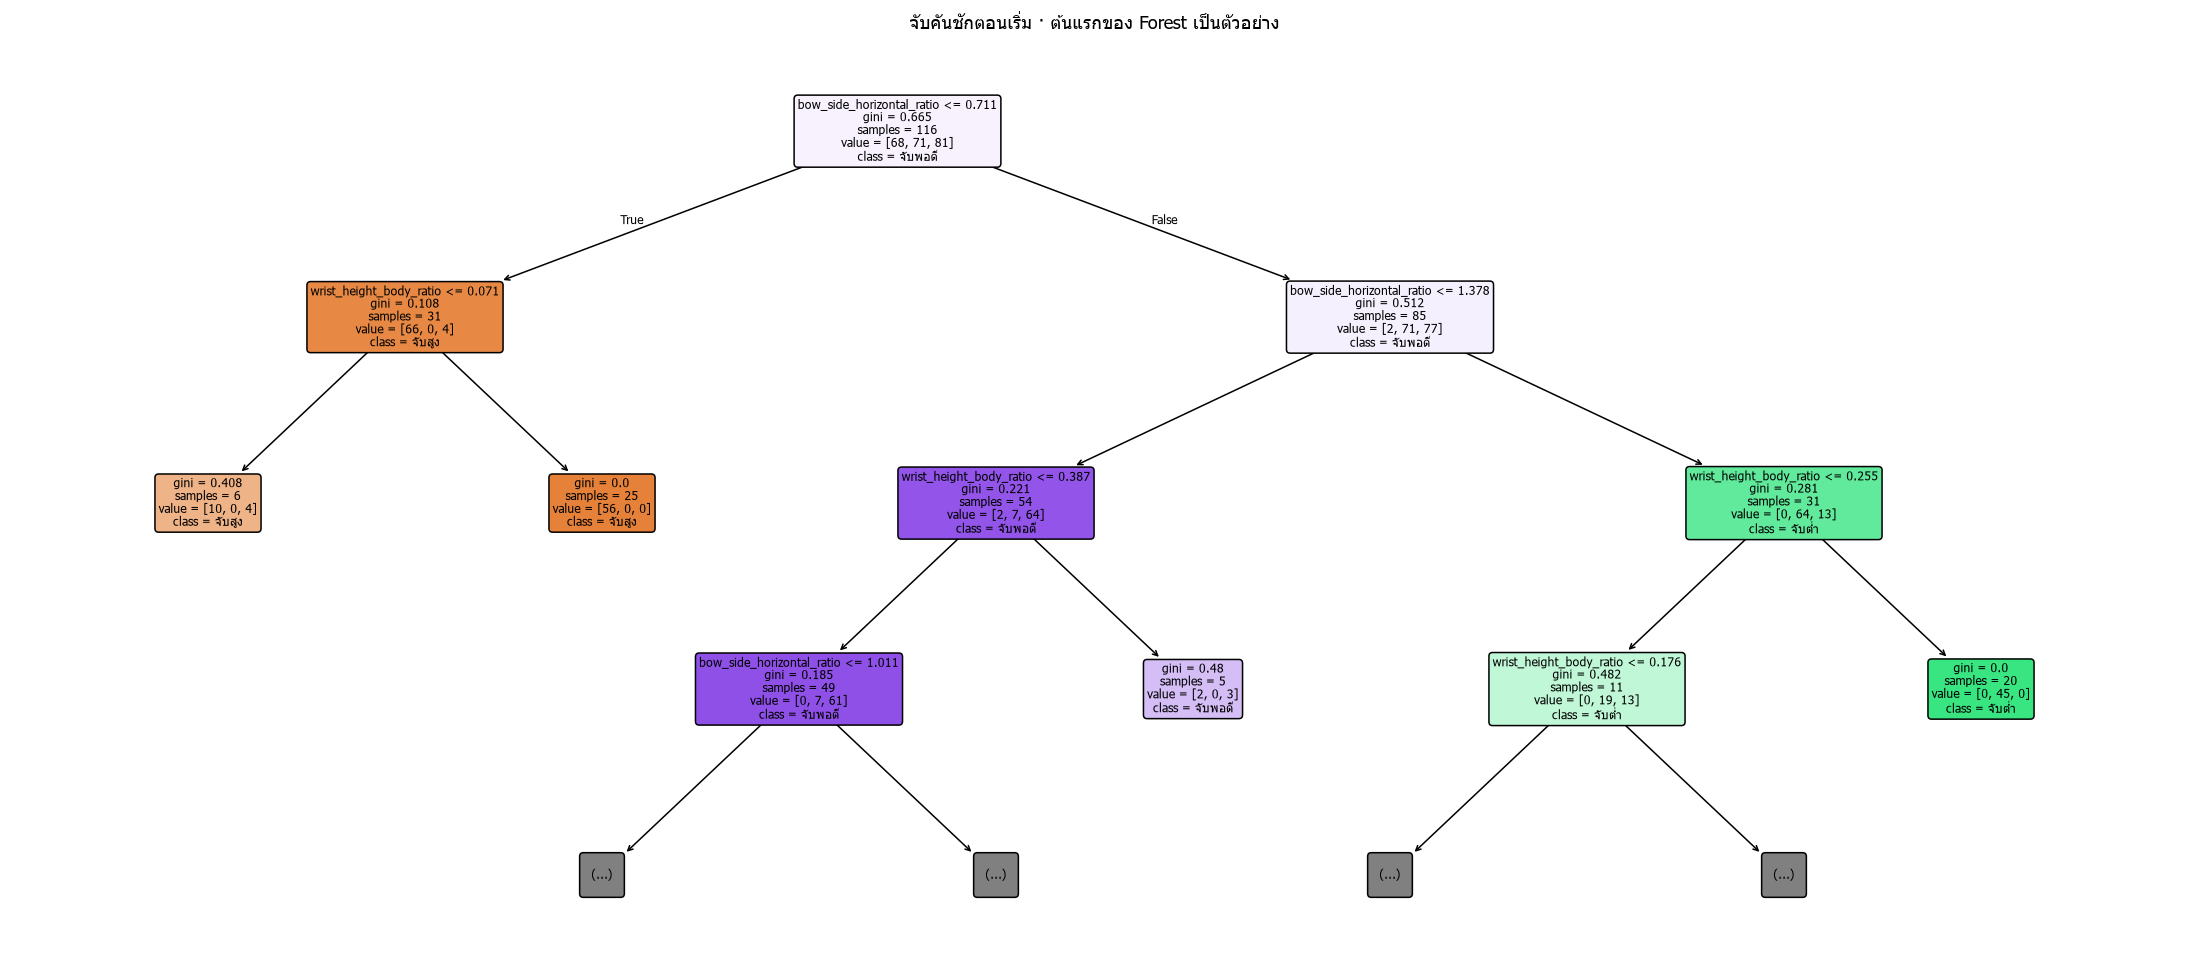

In [25]:
bundle = final_bundles['initial_grip']
fig = ce.plot_model_tree(bundle,'จับคันชักตอนเริ่ม')
fig.savefig(REPORT/'tree_initial_grip.png',dpi=130); plt.show()
ce.save_tree_rules(bundle,REPORT/'rules_initial_grip.txt')

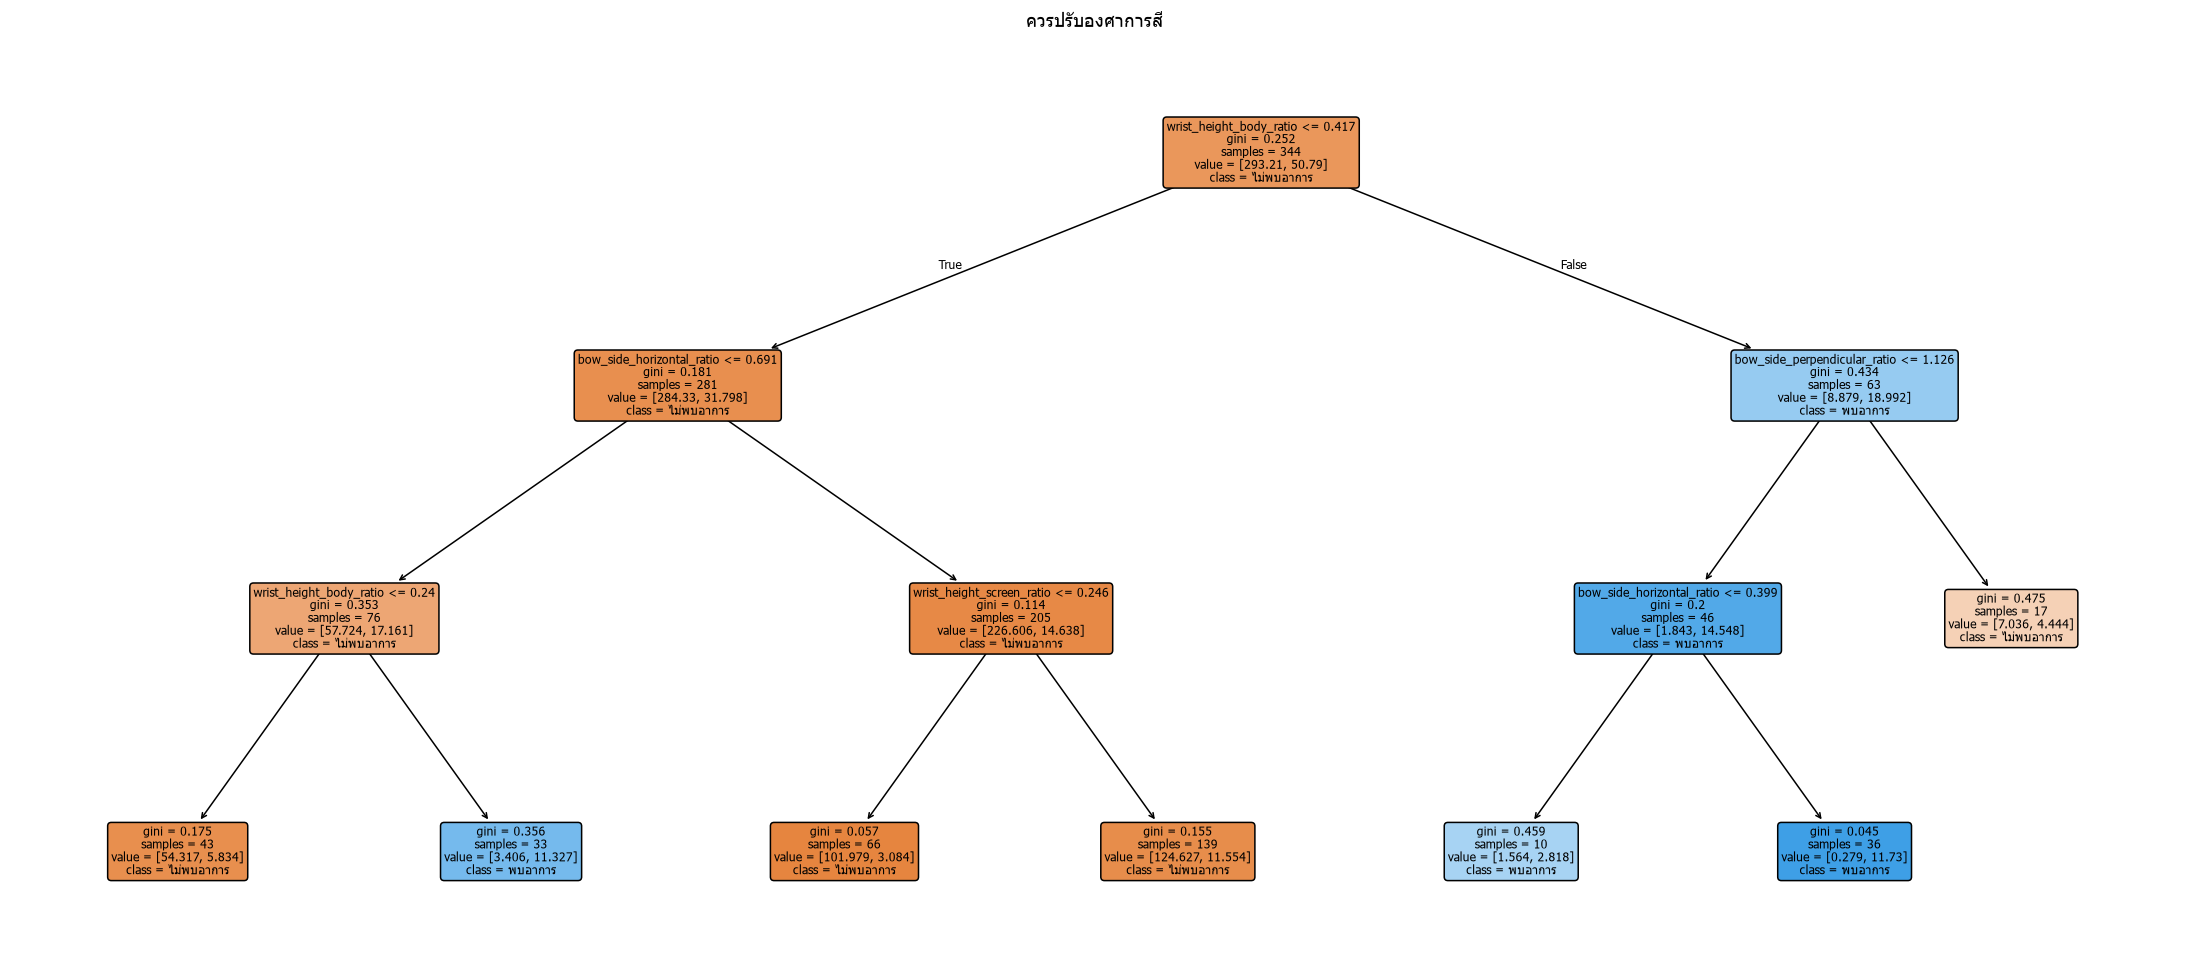

In [26]:
bundle = final_bundles['bow_error']
fig = ce.plot_model_tree(bundle,'ควรปรับองศาการสี')
fig.savefig(REPORT/'tree_bow_error.png',dpi=130); plt.show()
ce.save_tree_rules(bundle,REPORT/'rules_bow_error.txt')

## 8.1 · บันทึกหลักฐานและยืนยันว่าเว็บยังใช้รุ่นเดิม
Artifact ที่ได้ยังเป็นชุดสำหรับประเมิน ไม่ใช่การนำไปใช้ในเว็บ
เก็บเวอร์ชัน sklearn, hash ข้อมูล/โค้ด/โมเดล, รายการ clip ใน CV และตัวเลือกที่ล็อกแล้ว
การคาดการณ์ในรอบนี้เป็นคลาสตรงจากโมเดล ยังไม่ได้เพิ่ม guard ความไม่แน่ใจหรือ smoothing ของเว็บ

In [27]:
if TRAIN_NEW:
    record['tasks'] = {task:dict(selected=entry['selected'],
        validation_model_sha256=ce.sha256(MODEL_DIR/'validation'/f'{task}.joblib'),
        final_model_sha256=ce.sha256(MODEL_DIR/'final'/f'{task}.joblib'))
        for task,entry in selection.items()}
    record['source_hashes'] = record.get('source_hashes') or {
        'training_helpers':ce.sha256(ce.ROOT/'src/training/combined_experts.py'),
        'notebook_builder':ce.sha256(ce.ROOT/'src/training/build_combined_notebooks.py'),
        'posture_geometry':ce.sha256(ce.ROOT/'src/data/posture_features.py'),
        'body_geometry':ce.sha256(ce.ROOT/'src/data/torso_hand_proxy.py')}
    record['web_after_training'] = ce.web_fingerprints()
    assert record['web_before'] == record['web_after_training'], 'Deployed model changed'
    record['training_complete'] = True
    record['deployed'] = False
    ce.save_json(REPORT/'training_record.json',record)
    ce.save_json(MODEL_DIR/'summary.json',record)
    print('Training complete:', RUN)
    print('Web model unchanged: verified')
    print('Next: 02_validation_results.ipynb → 03_test_results.ipynb')
else:
    assert WEB_BEFORE == ce.web_fingerprints(), 'Deployed model changed'
    print('Saved training run loaded; deployed model unchanged')


Training complete: combined_experts_20261007_211339_512861
Web model unchanged: verified
Next: 02_validation_results.ipynb → 03_test_results.ipynb


## 8.2 · ข้อจำกัดที่ต้องอ่านก่อนใช้คะแนน
- มีเพียงสองคน และแต่ละคนมีคลิปอยู่ทั้ง train/val/test จึงวัดคลิปที่กันไว้ของคนเดิม ไม่ใช่ความแม่นกับคนใหม่
- ข้อมูล expert01 บาง split เคยใช้ในการทดลองก่อนหน้าแล้ว แม้ไม่มีการรั่วของคลิปในรอบนี้ test จึงไม่ใช่ข้อมูลใหม่ทั้งหมด
- งานจับสูง–ต่ำตรวจเฉพาะท่าขวาสุดตอนเริ่ม ผลระหว่างการสีไม่อยู่ในขอบเขตการฝึกนี้
- งานองศาการสีใช้ body proxy จึงอาจแยกผิดเมื่อมือ/ลำตัวมีท่าคล้ายกัน
- คะแนนเฟรมที่ landmark ครบและคะแนนรวมเฟรมที่ landmark ไม่ครบแยกไว้ในเล่มประเมิน
- การเปิด TEST มีจุดประสงค์รายงาน ไม่ใช้ปรับพารามิเตอร์อีกในรอบนี้

## สรุปการฝึกรอบนี้จากผลจริง

Run: `combined_experts_20261007_211339_512861` · 240 configurations × 3 TRAIN folds = 720 CV fits

เลือกพารามิเตอร์จาก TRAIN CV ก่อน แล้วให้ผู้ชนะ Tree และ Forest เทียบกันบน VAL รุ่นสำหรับ VAL fit TRAIN เท่านั้น ส่วนรุ่นสุดท้าย fit TRAIN+VAL หลังล็อกตัวเลือก

### ก้มหน้า

random_forest · `posture_10` · `{'max_depth': None, 'max_features': 1.0, 'min_samples_leaf': 2, 'n_estimators': 150}` · `clip_class_balanced`

TRAIN-CV F1 **0.786**, VAL F1 **0.707**; fit สุดท้าย 1091 เฟรม

### ไหล่เอียง

random_forest · `posture_10` · `{'max_depth': 3, 'max_features': 1.0, 'min_samples_leaf': 2, 'n_estimators': 150}` · `clip_class_balanced`

TRAIN-CV F1 **0.787**, VAL F1 **0.749**; fit สุดท้าย 1091 เฟรม

### จับคันชักตอนเริ่ม

random_forest · `body_2` · `{'max_depth': 6, 'max_features': 1.0, 'min_samples_leaf': 5, 'n_estimators': 150}` · `clip_class_balanced`

TRAIN-CV F1 **0.794**, VAL F1 **0.732**; fit สุดท้าย 220 เฟรม

### ควรปรับองศาการสี

decision_tree · `body_4` · `{'max_depth': 3, 'min_samples_leaf': 10}` · `clip_equal`

TRAIN-CV F1 **0.717**, VAL F1 **0.827**; fit สุดท้าย 344 เฟรม